<a href="https://colab.research.google.com/github/itmepavan/Deep-Learning-week-1/blob/main/deep_learning_week3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Reshape((28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
model.fit(X_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 19ms/step - accuracy: 0.8562 - loss: 0.4105
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.8968 - loss: 0.2836
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9114 - loss: 0.2425
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.9223 - loss: 0.2116
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 20ms/step - accuracy: 0.9295 - loss: 0.1862


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predicted: Ankle boot
Actual: Ankle boot


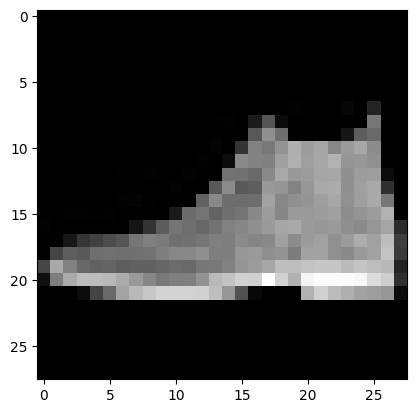

In [7]:
classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

prediction = model.predict(X_test)

i = 0
print("Predicted:", classes[np.argmax(prediction[i])])
print("Actual:", classes[y_test[i]])

plt.imshow(X_test[i], cmap='gray')
plt.show()

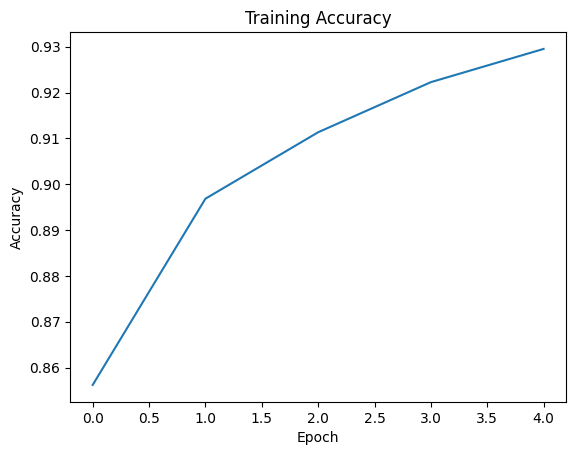

In [8]:
plt.plot(model.history.history['accuracy'])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


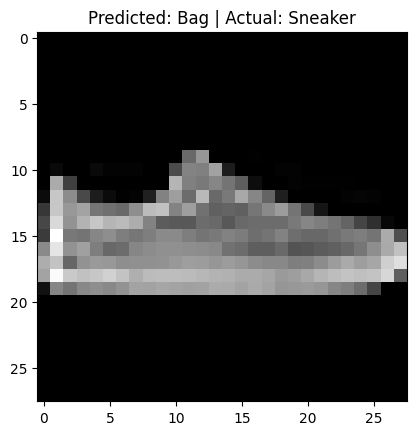

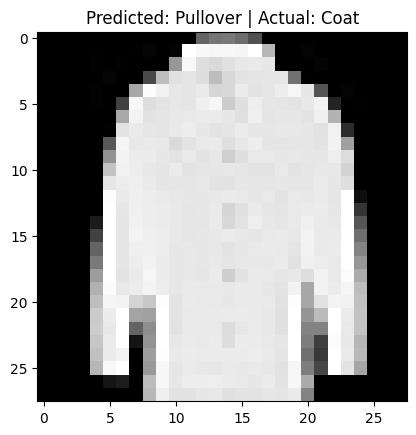

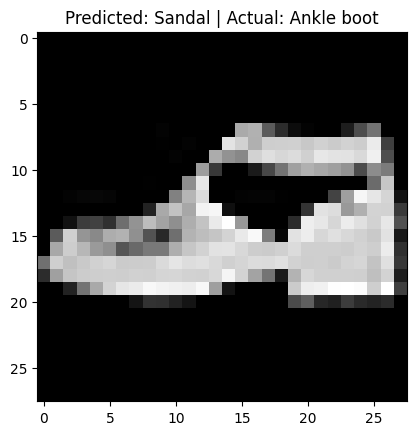

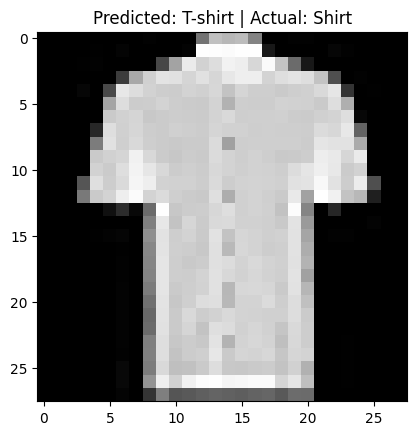

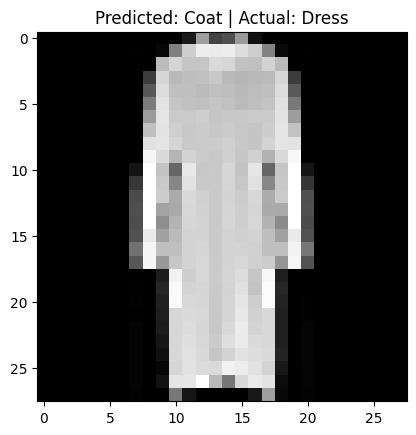

In [9]:
predictions = model.predict(X_test)

wrong = np.where(
    np.argmax(predictions, axis=1) != y_test
)[0]

for i in wrong[:5]:
    plt.imshow(X_test[i], cmap='gray')
    plt.title(
        "Predicted: " + classes[np.argmax(predictions[i])] +
        " | Actual: " + classes[y_test[i]]
    )
    plt.show()

In [10]:
model.save("fashion_model.keras")
print("Model saved successfully!")

Model saved successfully!
